# Building Energy Analyzer - Analysis Notebook

This notebook explains the analysis step by step. It uses the same functions as `main.py`:

* `module1_rooms.py` - the `Room` class and room functions (Module 1)
* `module2_analysis.py` - pandas, NumPy and Matplotlib analysis (Module 2)

**Run it from the project folder** (the folder that contains `main.py`).

## 1. Module 1 - rooms and their estimated energy

Estimated daily energy (kWh) = total power (kW) x operating hours.
Consumption per m2 = daily energy / room area.

In [1]:
import module1_rooms as m1

rooms = m1.load_rooms("data/rooms.csv")
m1.list_rooms(rooms)
print()
print("Total estimated consumption:", round(m1.total_consumption(rooms), 1), "kWh/day")
print("Buildings:", sorted(m1.buildings(rooms)))

ID   Room            Building          Area     kW  Hours  kWh/day  kWh/m2
R01  Open Office     Admin Block        120   14.3     10    143.0    1.19
R02  Meeting Room    Admin Block         35    4.8      6     28.8    0.82
R03  Manager Office  Admin Block         28    3.7      8     29.6    1.06
R04  Server Room     Admin Block         20   13.2     24    316.8   15.84
R05  Lecture Hall    Academic Block     150   16.4      8    131.2    0.87
R06  Computer Lab    Academic Block      80   14.7      9    132.3    1.65
R07  Library         Academic Block     200   18.5     10    185.0    0.93
R08  Cafeteria       Academic Block      90   12.0      7     84.0    0.93

Total estimated consumption: 1050.7 kWh/day
Buildings: ['Academic Block', 'Admin Block']


## 2. Module 2 - clean and merge the readings (pandas)

Three cleaning steps: remove duplicate rows, fill missing kWh values with the average of the same room, then merge the readings with the room data using `room_id`.

In [2]:
import module2_analysis as m2

merged, log = m2.load_and_clean("data/rooms.csv", "data/readings.csv")
print(log)
merged.head()

{'rows_before': 490, 'duplicates_removed': 2, 'missing_values_filled': 3, 'rows_dropped_unknown_room': 0, 'rows_after': 488}


  room_id       date  actual_kwh  ... ac_kw equipment_kw hours_per_day
0     R01 2026-08-01       59.10  ...   9.0          3.5            10
1     R01 2026-08-02       61.95  ...   9.0          3.5            10
2     R01 2026-08-03      112.76  ...   9.0          3.5            10
3     R01 2026-08-04      117.46  ...   9.0          3.5            10
4     R01 2026-08-05      107.23  ...   9.0          3.5            10

[5 rows x 11 columns]

## 3. Consumption and cost

Cost = actual kWh x price per kWh. The price below is only an example; in `main.py` the user types it.

In [3]:
price = 2.0
by_room, by_building, by_month = m2.cost_tables(merged, price)
print(by_room.to_string(index=False)); print()
print(by_building.to_string(index=False)); print()
print(by_month.to_string(index=False))

room_id      room_name  actual_kwh     cost
    R01    Open Office     5540.51 11081.02
    R02   Meeting Room     1094.76  2189.52
    R03 Manager Office     1109.19  2218.38
    R04    Server Room    14568.91 29137.83
    R05   Lecture Hall     4989.56  9979.12
    R06   Computer Lab     5254.92 10509.84
    R07        Library     7726.55 15453.11
    R08      Cafeteria     3473.11  6946.21

      building  actual_kwh     cost
Academic Block    21444.14 42888.28
   Admin Block    22313.37 44626.75

  month  actual_kwh     cost
2026-08    23613.03 47226.06
2026-09    20144.49 40288.97


## 4. Descriptive statistics (Lecture 4)

Mean = centre of the readings. Standard deviation = spread. c.v. = spread / mean x 100 %. A small c.v. means a steady room (the server room runs all day, every day).

In [4]:
m2.room_statistics(merged)

        room_name    mean    std  cv_percent
0       Cafeteria   56.94   9.59       16.85
1    Computer Lab   86.15  21.27       24.70
2    Lecture Hall   81.80  21.32       26.06
3         Library  126.66  15.08       11.91
4  Manager Office   18.18   4.75       26.10
5    Meeting Room   17.95   4.67       26.02
6     Open Office   90.83  23.36       25.72
7     Server Room  238.83  13.83        5.79

## 5. Air-conditioning reduction (NumPy)

Only the AC power is reduced; operating hours and the other power values stay the same. This is an **estimate** (it uses the Module 1 formula).

In [5]:
scenario = m2.ac_reduction("data/rooms.csv", 20)
print(scenario.to_string(index=False))
before = scenario["before_kwh"].sum()
saved = scenario["saved_kwh"].sum()
print("\nBefore:", round(before, 1), "kWh/day | Saved:", round(saved, 1), "kWh/day (", round(saved / before * 100, 1), "%)")

room_id      room_name  before_kwh  after_kwh  saved_kwh
    R01    Open Office       143.0     125.00      18.00
    R02   Meeting Room        28.8      24.60       4.20
    R03 Manager Office        29.6      25.12       4.48
    R04    Server Room       316.8     292.80      24.00
    R05   Lecture Hall       131.2     112.00      19.20
    R06   Computer Lab       132.3     119.70      12.60
    R07        Library       185.0     157.00      28.00
    R08      Cafeteria        84.0      75.60       8.40

Before: 1050.7 kWh/day | Saved: 118.9 kWh/day ( 11.3 %)


## 6. Linear regression (Lecture 5)

Does a bigger room use more energy? We fit the line `y = a0 + a1 x` with the slope and intercept formulas from the lecture.

In [6]:
import numpy as np

per_room = merged.groupby("room_id").agg(area=("area_m2", "first"), average=("actual_kwh", "mean"))
a1, a0, r2 = m2.linear_fit(per_room["area"].to_numpy(), per_room["average"].to_numpy())
print("slope a1 =", round(a1, 3), "kWh per m2 | intercept a0 =", round(a0, 2), "| r2 =", round(r2, 3))

slope a1 = 0.056 kWh per m2 | intercept a0 = 84.58 | r2 = 0.003


## 7. The four charts

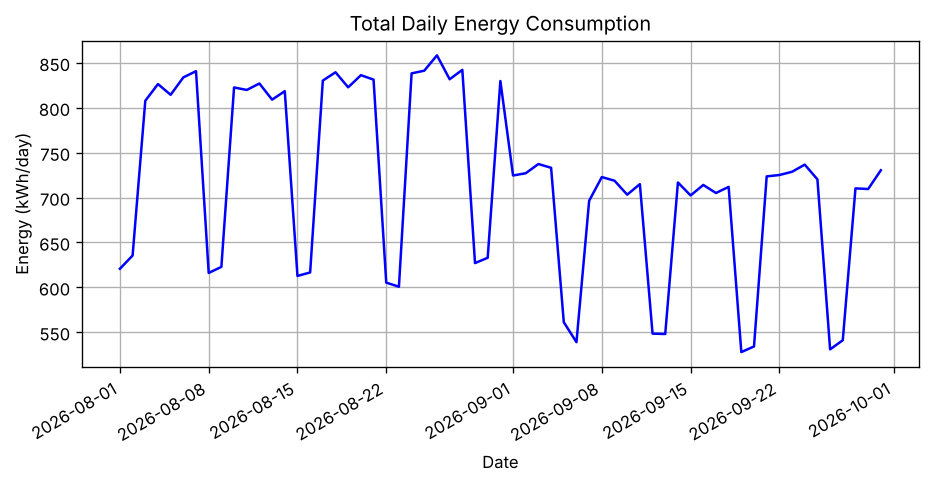

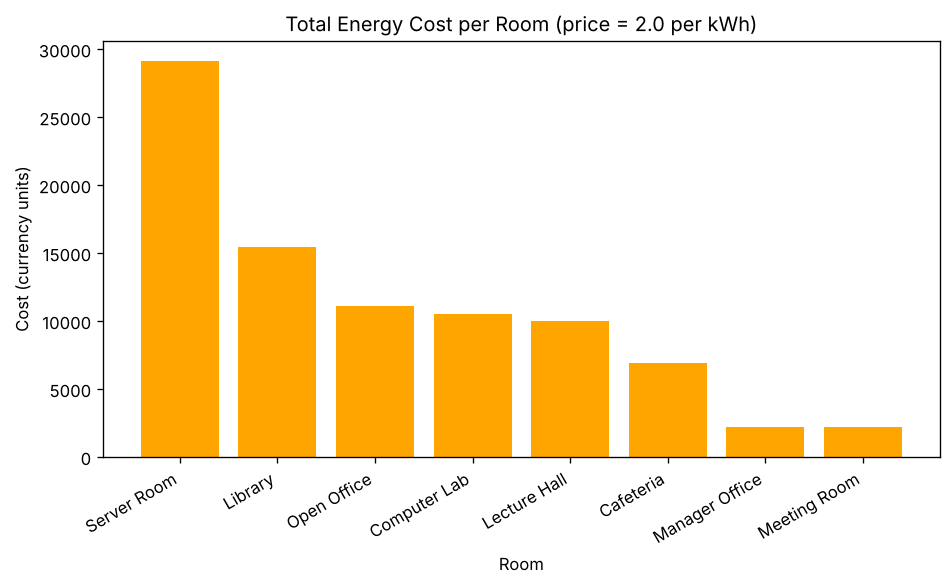

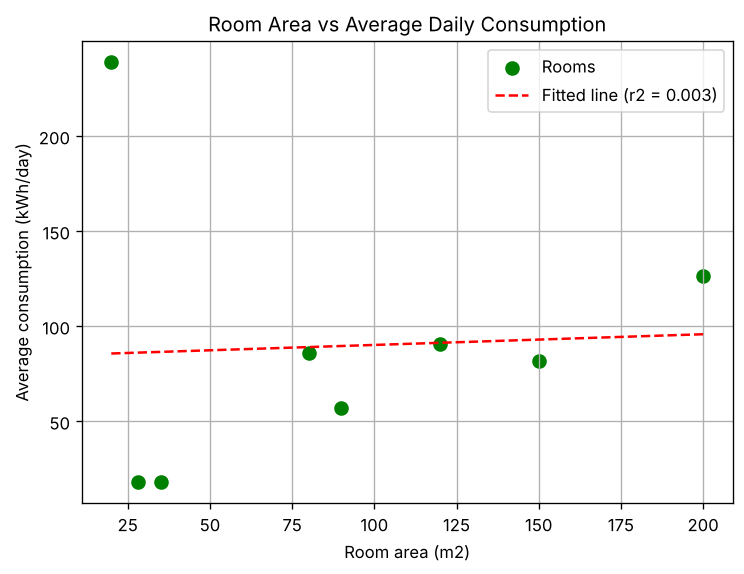

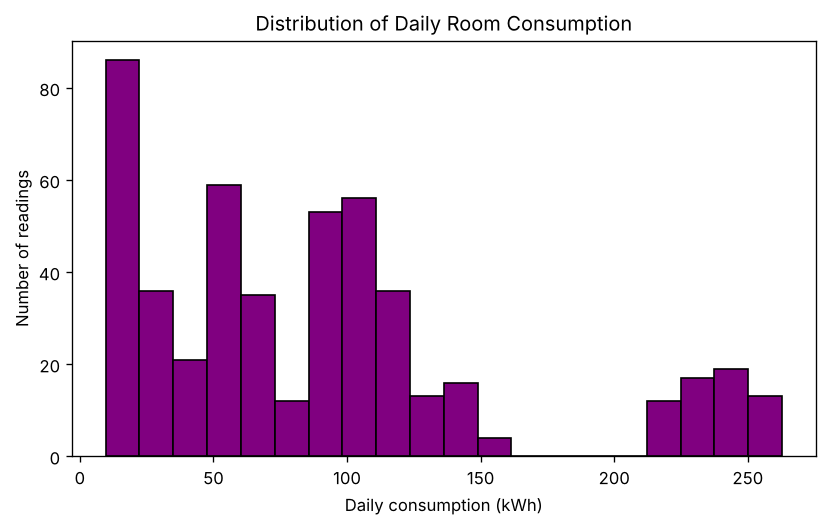

In [7]:
from IPython.display import Image, display

paths = m2.make_charts(merged, price, "outputs/charts")
for path in paths:
    display(Image(path))

## Conclusions

* Total actual consumption is about 43,758 kWh in 61 days. The Server Room is the biggest consumer (about a third of the energy) because it runs 24 hours.
* September used less energy than August.
* Actual consumption is lower than the Module 1 estimate in every room (about 25 % to 39 % lower), so the estimate is a safe upper value.
* Room area does not explain consumption (r2 is almost 0): the small Server Room uses far more than the big Lecture Hall. Power and hours matter more than area.
* Reducing AC power by 20 % saves about 11.3 % of the estimated daily energy.